# PRAKTIKUM PENGOLAHAN SINYAL DIGITAL (PSD)
## Modul: Ekstraksi 14 Fitur Citra Digital & Pemodelan Klasifikasi (Alur Sinyal Audio)
**Program Studi Teknik Informatika - Universitas Trunojoyo Madura**

---

### Identitas Mahasiswa:
- **Nama** : Muhammad Zaidan Nabil Rafi
- **NIM**  : 240411100068
- **Kelas/Mata Kuliah** : Pengolahan Sinyal Digital (PSD)

---

### Deskripsi Proyek:
Notebook ini merupakan dokumen demonstrasi dan pengujian lengkap untuk tugas praktikum klasifikasi citra digital kondisi ruangan (**Berantakan** vs **Rapi**) menggunakan **14 Fitur Inti Dosen**:
1. **Domain Warna RGB (9 Fitur):** `mean_r`, `std_r`, `skew_r`, `mean_g`, `std_g`, `skew_g`, `mean_b`, `std_b`, `skew_b`
2. **Domain Tekstur Spasial GLCM Grayscale 8-bit (5 Fitur Haralick):** `glcm_energy`, `glcm_entropy`, `glcm_contrast`, `glcm_correlation`, `glcm_homogeneity`
3. **Dataset CSV:** Disimpan dalam `hasil_ekstraksi_fitur_citra.csv` (194 citra: 97 Rapi vs 97 Berantakan).
4. **Metodologi Klasifikasi:** Stratified Split 80:20, StandardScaler, SVM RBF, Random Forest, Logistic Regression, 5-Fold Cross Validation, dan *Live Inference Testing*.

## 1. Landasan Teori & Formula Matematis Ekstraksi Fitur

### A. Konversi Citra ke Grayscale 8-bit (Standar ITU-R BT.601)
Citra berwarna RGB dikonversi ke derajat keabuan 8-bit ($Y \in [0, 255]$) menggunakan kombinasi linear luminansi persepsi visual manusia:
$$Y = 0.299 \cdot R + 0.587 \cdot G + 0.114 \cdot B$$

### B. Momen Statistik Warna RGB per Kanal ($c \in \{R, G, B\}$)
1. **Rata-rata Intensitas (*Mean*):**
   $$\mu_c = rac{1}{N} \sum_{i=1}^{N} I_c(i)$$
2. **Standar Deviasi (*Standard Deviation*):**
   $$\sigma_c = \sqrt{rac{1}{N} \sum_{i=1}^{N} (I_c(i) - \mu_c)^2}$$
3. **Kemiringan Distribusi (*Skewness*):**
   $$S_c = rac{rac{1}{N} \sum_{i=1}^{N} (I_c(i) - \mu_c)^3}{\sigma_c^3}$$

### C. Fitur Tekstur Spasial GLCM Haralick (4 Sudut Orientasi: $0^\circ, 45^\circ, 90^\circ, 135^\circ$)
Dengan $P(i, j)$ merupakan matriks probabilitas kookurensi ternormalisasi:
1. **Kontras (*Contrast*):** Mengukur variasi intensitas lokal antar piksel bertetangga.
   $$	ext{Contrast} = \sum_{i} \sum_{j} (i - j)^2 P(i, j)$$
2. **Homogenitas (*Homogeneity / IDM*):** Mengukur keseragaman keabuan permukaan.
   $$	ext{Homogeneity} = \sum_{i} \sum_{j} rac{P(i, j)}{1 + |i - j|}$$
3. **Energi (*Energy / ASM*):** Mengukur keteraturan dan pengulangan pola tekstur.
   $$	ext{Energy} = \sum_{i} \sum_{j} P(i, j)^2$$
4. **Entropi (*Entropy*):** Mengukur tingkat ketidakpastian atau keacakan spasial informasi.
   $$	ext{Entropy} = -\sum_{i} \sum_{j} P(i, j) \log_2 P(i, j)$$
5. **Korelasi (*Correlation*):** Mengukur ketergantungan linier nilai keabuan antar pasangan piksel.
   $$	ext{Correlation} = \sum_{i} \sum_{j} rac{(i - \mu_i)(j - \mu_j) P(i, j)}{\sigma_i \sigma_j}$$

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# =============================================================================
# 1. FUNGSI EKSTRAKSI 5 FITUR GLCM TEKSTUR HARALICK
# =============================================================================
def hitung_glcm_5_fitur(gray_img, n_levels=64, distance=1):
    scaled = (gray_img.astype(np.float32) / 256.0 * n_levels).astype(np.uint32)
    scaled = np.clip(scaled, 0, n_levels - 1)
    H, W = scaled.shape
    
    # 4 Arah orientasi spasial: 0, 45, 90, 135 derajat
    directions = [(0, 1), (-1, 1), (-1, 0), (-1, -1)]
    d = distance
    
    all_contrasts, all_homogeneities = [], []
    all_energies, all_correlations, all_entropies = [], [], []
    
    for dy, dx in directions:
        y1_s = max(0, -dy * d); y1_e = min(H, H - dy * d)
        x1_s = max(0, -dx * d); x1_e = min(W, W - dx * d)
        y2_s = max(0, dy * d);  y2_e = min(H, H + dy * d)
        x2_s = max(0, dx * d);  x2_e = min(W, W + dx * d)
        
        p1 = scaled[y1_s:y1_e, x1_s:x1_e].ravel()
        p2 = scaled[y2_s:y2_e, x2_s:x2_e].ravel()
        
        mat, _, _ = np.histogram2d(p1, p2, bins=n_levels, range=[[0, n_levels], [0, n_levels]])
        mat = mat + mat.T  # Matriks simetris
        tot = mat.sum()
        p = mat / tot if tot > 0 else mat
        
        i_idx, j_idx = np.indices((n_levels, n_levels))
        diff = np.abs(i_idx - j_idx)
        diff_sq = diff ** 2
        
        contrast = np.sum(diff_sq * p)
        homogeneity = np.sum(p / (1.0 + diff))
        energy = np.sum(p ** 2)
        
        nonzero_p = p[p > 0]
        entropy = -np.sum(nonzero_p * np.log2(nonzero_p)) if len(nonzero_p) > 0 else 0.0
        
        mu_i = np.sum(i_idx * p)
        mu_j = np.sum(j_idx * p)
        var_i = np.sum(((i_idx - mu_i) ** 2) * p)
        var_j = np.sum(((j_idx - mu_j) ** 2) * p)
        std_ij = np.sqrt(var_i * var_j)
        corr = np.sum((i_idx - mu_i) * (j_idx - mu_j) * p) / std_ij if std_ij > 1e-9 else 1.0
        
        all_contrasts.append(contrast)
        all_homogeneities.append(homogeneity)
        all_energies.append(energy)
        all_correlations.append(corr)
        all_entropies.append(entropy)
        
    return {
        'glcm_energy': float(np.mean(all_energies)),
        'glcm_entropy': float(np.mean(all_entropies)),
        'glcm_contrast': float(np.mean(all_contrasts)),
        'glcm_correlation': float(np.mean(all_correlations)),
        'glcm_homogeneity': float(np.mean(all_homogeneities))
    }

# =============================================================================
# 2. FUNGSI EKSTRAKSI 14 FITUR (WARNA + GLCM) PADA 1 CITRA
# =============================================================================
def ekstraksi_14_fitur(citra_input):
    if isinstance(citra_input, str):
        img_bgr = cv2.imread(citra_input)
    else:
        img_bgr = citra_input
        
    # Preprocessing 1: Standarisasi resolusi 512x512
    img_std = cv2.resize(img_bgr, (512, 512), interpolation=cv2.INTER_AREA)
    
    # Preprocessing 2: BGR -> RGB
    img_rgb = cv2.cvtColor(img_std, cv2.COLOR_BGR2RGB)
    
    # Preprocessing 3: RGB -> Grayscale 8-bit (ITU-R BT.601)
    gray = cv2.cvtColor(img_std, cv2.COLOR_BGR2GRAY)
    
    feats = {}
    # A. 9 Momen Warna RGB
    for idx, c in enumerate(['r', 'g', 'b']):
        vals = img_rgb[:, :, idx].astype(np.float64)
        feats[f'mean_{c}'] = float(np.mean(vals))
        feats[f'std_{c}']  = float(np.std(vals))
        feats[f'skew_{c}'] = float(stats.skew(vals.ravel()))
        
    # B. 5 Fitur Tekstur GLCM
    glcm_dict = hitung_glcm_5_fitur(gray, n_levels=64, distance=1)
    feats.update(glcm_dict)
    
    return feats, img_rgb, gray

print("Fungsi ekstraksi 14 fitur berhasil didefinisikan!")

Fungsi ekstraksi 14 fitur berhasil didefinisikan!


## 2. Pengujian Ekstraksi pada Citra Mahasiswa Sendiri (`24-068`)

Pada tahap ini, kita mengekstraksi dan membandingkan secara langsung dua citra milik **Muhammad Zaidan Nabil Rafi (NIM: 24-068)**:
1. `24-068 Berantakan 1.jpeg` (Kondisi Meja Belajar Berantakan)
2. `24-068 Rapi 1.jpeg` (Kondisi Meja Belajar Rapi)

Kita juga memvisualisasikan dekomposisi ruang warna RGB dan representasi derajat keabuan (Grayscale).

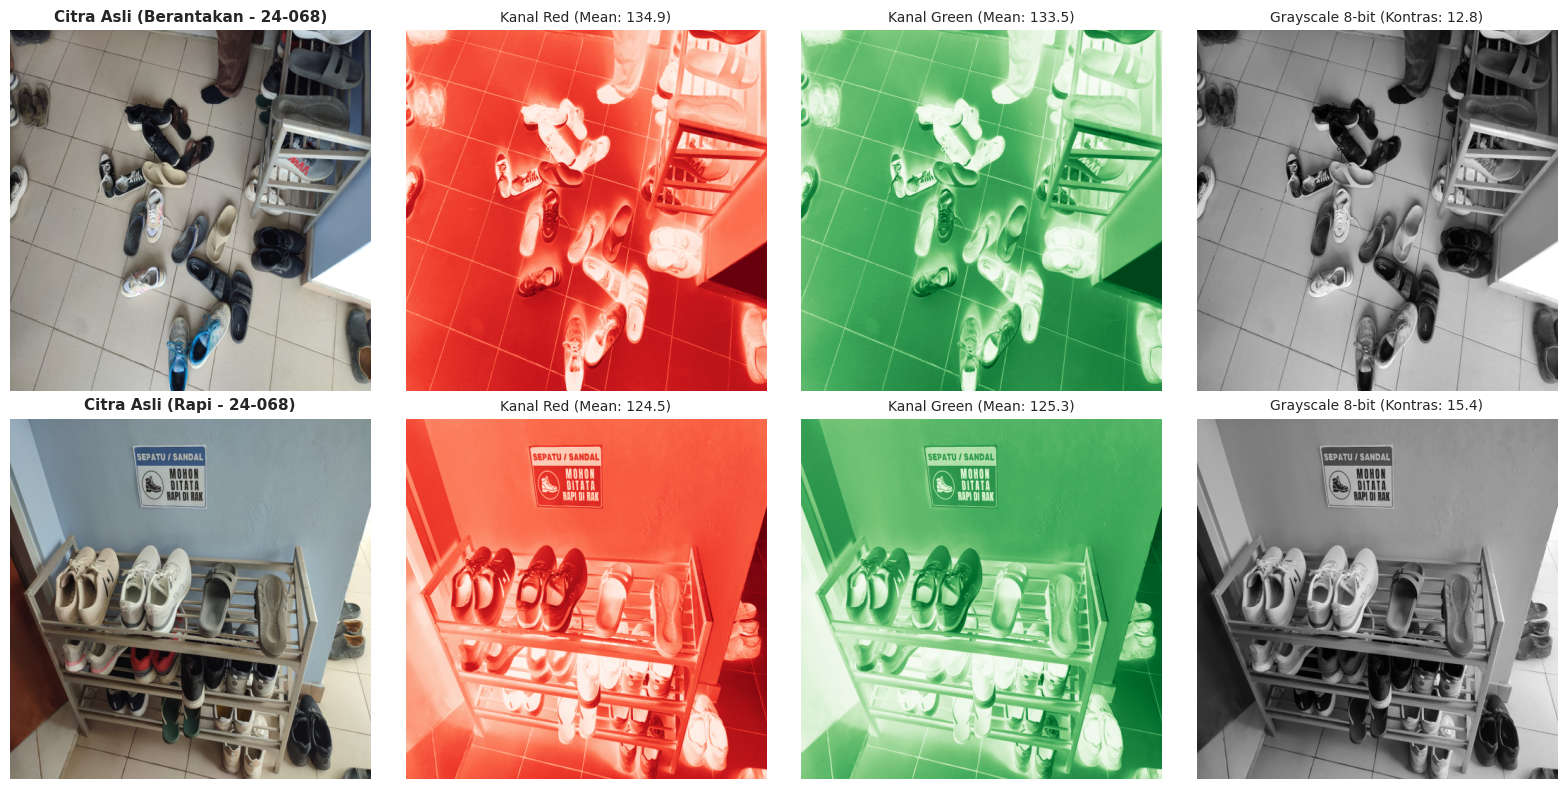

,Nama Fitur,Nilai (Berantakan),Nilai (Rapi),Domain Fitur
1,mean_r,134.89879,124.46167,Warna R (Mean)
2,std_r,55.54135,48.49903,Warna R (Std)
3,skew_r,-0.58299,-0.13906,Warna R (Skewness)
4,mean_g,133.48738,125.31627,Warna G (Mean)
5,std_g,54.40930,54.13625,Warna G (Std)
6,skew_g,-0.54035,-0.41899,Warna G (Skewness)
7,mean_b,128.89809,120.71827,Warna B (Mean)
8,std_b,51.46392,55.59013,Warna B (Std)
9,skew_b,-0.41564,-0.46567,Warna B (Skewness)
10,glcm_energy,0.00900,0.01043,Tekstur GLCM (Energi / ASM)


In [2]:
path_berantakan = r"dataset_baru/berantakan/24-068 Berantakan 1.jpeg"
path_rapi = r"dataset_baru/rapi/24-068 Rapi 1.jpeg"

feats_b, rgb_b, gray_b = ekstraksi_14_fitur(path_berantakan)
feats_r, rgb_r, gray_r = ekstraksi_14_fitur(path_rapi)

# Visualisasi Citra Asli, Dekomposisi Warna, dan Grayscale
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

# Baris 1: Citra Berantakan
axes[0, 0].imshow(rgb_b); axes[0, 0].set_title("Citra Asli (Berantakan - 24-068)", fontsize=11, fontweight='bold'); axes[0, 0].axis('off')
axes[0, 1].imshow(rgb_b[:, :, 0], cmap='Reds'); axes[0, 1].set_title(f"Kanal Red (Mean: {feats_b['mean_r']:.1f})", fontsize=10); axes[0, 1].axis('off')
axes[0, 2].imshow(rgb_b[:, :, 1], cmap='Greens'); axes[0, 2].set_title(f"Kanal Green (Mean: {feats_b['mean_g']:.1f})", fontsize=10); axes[0, 2].axis('off')
axes[0, 3].imshow(gray_b, cmap='gray'); axes[0, 3].set_title(f"Grayscale 8-bit (Kontras: {feats_b['glcm_contrast']:.1f})", fontsize=10); axes[0, 3].axis('off')

# Baris 2: Citra Rapi
axes[1, 0].imshow(rgb_r); axes[1, 0].set_title("Citra Asli (Rapi - 24-068)", fontsize=11, fontweight='bold'); axes[1, 0].axis('off')
axes[1, 1].imshow(rgb_r[:, :, 0], cmap='Reds'); axes[1, 1].set_title(f"Kanal Red (Mean: {feats_r['mean_r']:.1f})", fontsize=10); axes[1, 1].axis('off')
axes[1, 2].imshow(rgb_r[:, :, 1], cmap='Greens'); axes[1, 2].set_title(f"Kanal Green (Mean: {feats_r['mean_g']:.1f})", fontsize=10); axes[1, 2].axis('off')
axes[1, 3].imshow(gray_r, cmap='gray'); axes[1, 3].set_title(f"Grayscale 8-bit (Kontras: {feats_r['glcm_contrast']:.1f})", fontsize=10); axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

# Tampilkan Tabel Perbandingan 14 Fitur Berdampingan
df_komparasi = pd.DataFrame({
    'Nama Fitur': list(feats_b.keys()),
    'Nilai (Berantakan)': [f"{v:.5f}" for v in feats_b.values()],
    'Nilai (Rapi)': [f"{v:.5f}" for v in feats_r.values()],
    'Domain Fitur': [
        'Warna R (Mean)', 'Warna R (Std)', 'Warna R (Skewness)',
        'Warna G (Mean)', 'Warna G (Std)', 'Warna G (Skewness)',
        'Warna B (Mean)', 'Warna B (Std)', 'Warna B (Skewness)',
        'Tekstur GLCM (Energi / ASM)', 'Tekstur GLCM (Entropi Keacakan)',
        'Tekstur GLCM (Kontras Lokal)', 'Tekstur GLCM (Korelasi Linier)',
        'Tekstur GLCM (Homogenitas / IDM)'
    ]
})
df_komparasi.index += 1
display(df_komparasi)

## 3. Pembacaan Dataset CSV (194 Citra) & Eksplorasi Data (EDA)

Dataset hasil ekstraksi 14 fitur dari seluruh 194 citra tersimpan dalam berkas:
`hasil_ekstraksi_fitur_citra.csv`

Kita memeriksa distribusi sampel, memastikan data seimbang (*balanced binary*), dan melihat daya pisah visual fitur-fitur kunci.

Total Sampel Citra : 194
Jumlah Kolom       : 16 (1 filename, 14 fitur, 1 label)
Distribusi Kelas   : {'Berantakan': 97, 'Rapi': 97}
Missing Values     : 0 (Data 100% Bersih)


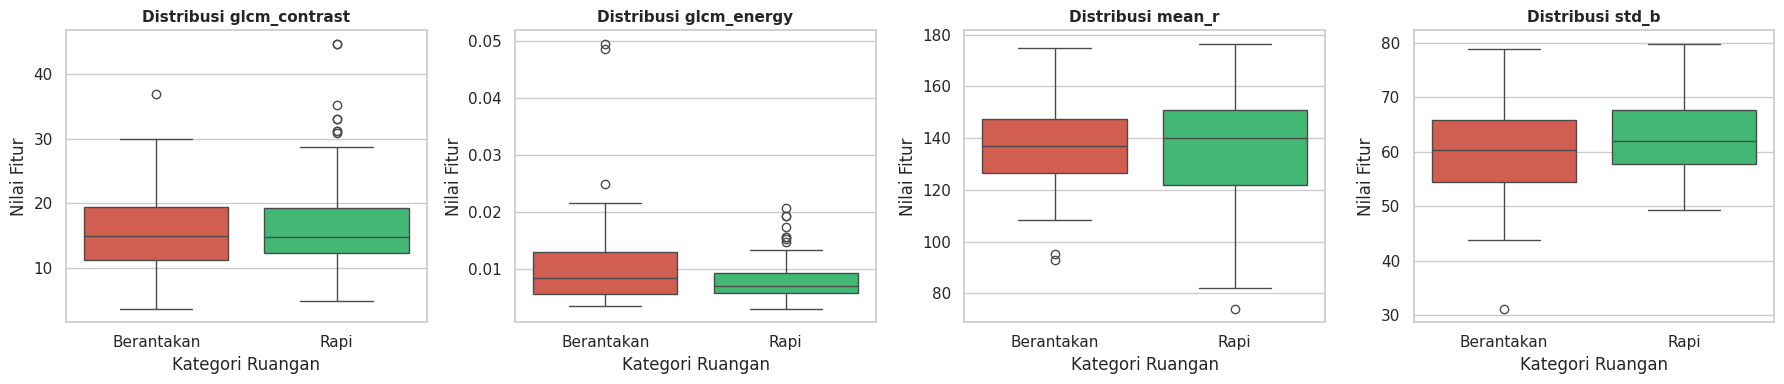

,Mean (Berantakan),Mean (Rapi),Delta Selisih
mean_r,136.8201,136.2082,0.6118
std_r,59.5834,57.4544,2.1290
skew_r,-0.3165,-0.2637,-0.0528
mean_g,126.7677,126.6029,0.1647
std_g,60.1019,60.3607,-0.2588
skew_g,-0.1305,-0.0652,-0.0654
mean_b,117.9490,120.0485,-2.0994
std_b,60.0360,62.4792,-2.4432
skew_b,-0.0362,-0.0442,0.0079
glcm_energy,0.0104,0.0081,0.0023


In [3]:
csv_file = 'hasil_ekstraksi_fitur_citra.csv'
df = pd.read_csv(csv_file)

print(f"Total Sampel Citra : {len(df)}")
print(f"Jumlah Kolom       : {df.shape[1]} (1 filename, 14 fitur, 1 label)")
print(f"Distribusi Kelas   : {df['label'].value_counts().to_dict()}")
print(f"Missing Values     : {df.isna().sum().sum()} (Data 100% Bersih)")

# Visualisasi Boxplot Distribusi Fitur Kunci
fitur_plot = ['glcm_contrast', 'glcm_energy', 'mean_r', 'std_b']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for idx, col in enumerate(fitur_plot):
    sns.boxplot(data=df, x='label', y=col, ax=axes[idx], palette=['#e74c3c', '#2ecc71'])
    axes[idx].set_title(f"Distribusi {col}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Kategori Ruangan")
    axes[idx].set_ylabel("Nilai Fitur")

plt.tight_layout()
plt.show()

# Ringkasan Statistik 14 Fitur per Kelas
features = [
    'mean_r', 'std_r', 'skew_r',
    'mean_g', 'std_g', 'skew_g',
    'mean_b', 'std_b', 'skew_b',
    'glcm_energy', 'glcm_entropy', 'glcm_contrast', 'glcm_correlation', 'glcm_homogeneity'
]
df_stats = df.groupby('label')[features].mean().T
df_stats.columns = ['Mean (Berantakan)', 'Mean (Rapi)']
df_stats['Delta Selisih'] = df_stats['Mean (Berantakan)'] - df_stats['Mean (Rapi)']
display(df_stats.round(4))

## 4. Pemodelan Klasifikasi Machine Learning & Matriks Akurasi (Alur Audio)

Mengikuti alur standar pengolahan sinyal audio kemarin:
1. **Stratified Split (80:20):** 155 data latih dan 39 data uji dengan proporsi kelas seimbang (50:50).
2. **StandardScaler (Z-Score):** Menstandarisasi fitur agar berskala seragam ($\mu = 0, \sigma = 1$).
3. **Model Klasifikasi:**
   - **Support Vector Machine (SVM RBF)** dengan regularisasi $C=5.0$.
   - **Random Forest Classifier** (100 Decision Trees, max_depth=6).
   - **Logistic Regression** (sebagai baseline linier).
4. **Validasi Silang (5-Fold Cross-Validation)** untuk menguji stabilitas generalisasi.
5. **Matriks Akurasi (*Confusion Matrix*)** untuk melihat True Positive, True Negative, False Positive, dan False Negative.

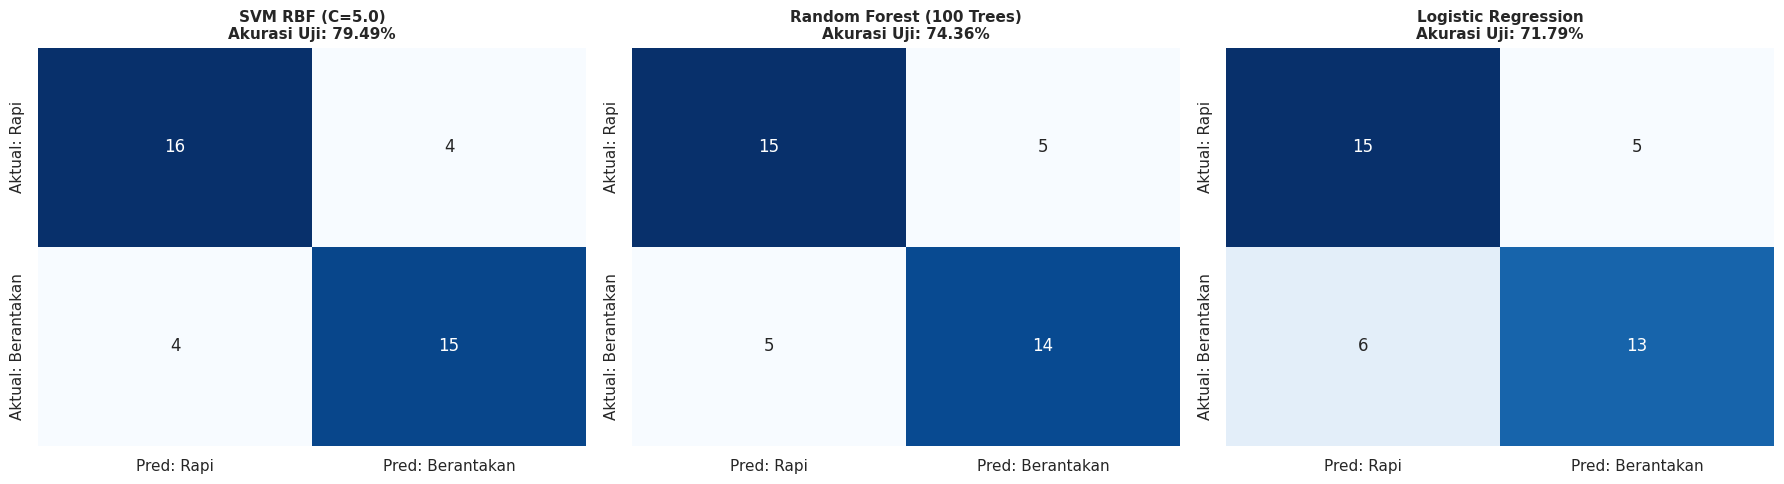

,Model,Train Acc (%),Test Acc (%),5-Fold CV (%),Precision (%),Recall (%),F1-Score (%)
0,SVM RBF (C=5.0),91.61%,79.49%,78.89% (±4.88%),78.95%,78.95%,78.95%
1,Random Forest (100 Trees),98.06%,74.36%,76.26% (±4.28%),73.68%,73.68%,73.68%
2,Logistic Regression,70.32%,71.79%,68.07% (±4.29%),72.22%,68.42%,70.27%



  LAPORAN KLASIFIKASI RINCI MODEL TERBAIK (SVM RBF)
                precision    recall  f1-score   support

      Rapi (0)       0.80      0.80      0.80        20
Berantakan (1)       0.79      0.79      0.79        19

      accuracy                           0.79        39
     macro avg       0.79      0.79      0.79        39
  weighted avg       0.79      0.79      0.79        39



In [4]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

X = df[features].values
y = (df['label'] == 'Berantakan').astype(int).values

# 1. Stratified Split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Standarisasi Z-Score
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)
X_all_sc = scaler.fit_transform(X)

# 3. Model Benchmark
models = {
    'SVM RBF (C=5.0)': SVC(kernel='rbf', C=5.0, probability=True, random_state=42),
    'Random Forest (100 Trees)': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
benchmark_results = []
trained_models = {}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, clf) in enumerate(models.items()):
    cv_scores = cross_val_score(clf, X_all_sc, y, cv=cv, scoring='accuracy')
    clf.fit(X_train_sc, y_train)
    trained_models[name] = clf
    
    y_train_pred = clf.predict(X_train_sc)
    y_test_pred = clf.predict(X_test_sc)
    
    train_acc = accuracy_score(y_train, y_train_pred) * 100
    test_acc = accuracy_score(y_test, y_test_pred) * 100
    prec = precision_score(y_test, y_test_pred) * 100
    rec = recall_score(y_test, y_test_pred) * 100
    f1 = f1_score(y_test, y_test_pred) * 100
    cm = confusion_matrix(y_test, y_test_pred)
    
    benchmark_results.append({
        'Model': name,
        'Train Acc (%)': f"{train_acc:.2f}%",
        'Test Acc (%)': f"{test_acc:.2f}%",
        '5-Fold CV (%)': f"{cv_scores.mean()*100:.2f}% (±{cv_scores.std()*100:.2f}%)",
        'Precision (%)': f"{prec:.2f}%",
        'Recall (%)': f"{rec:.2f}%",
        'F1-Score (%)': f"{f1:.2f}%"
    })
    
    # Plot Matriks Konfusi
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Pred: Rapi', 'Pred: Berantakan'],
                yticklabels=['Aktual: Rapi', 'Aktual: Berantakan'])
    axes[idx].set_title(f"{name}\nAkurasi Uji: {test_acc:.2f}%", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Tabel Benchmark
df_bench = pd.DataFrame(benchmark_results)
display(df_bench)

# Laporan Klasifikasi Rinci SVM
svm_clf = trained_models['SVM RBF (C=5.0)']
y_pred_svm = svm_clf.predict(X_test_sc)
print("\n" + "="*60)
print("  LAPORAN KLASIFIKASI RINCI MODEL TERBAIK (SVM RBF)")
print("="*60)
print(classification_report(y_test, y_pred_svm, target_names=['Rapi (0)', 'Berantakan (1)']))

## 5. Pengujian Prediksi Langsung (*Live Inference Testing*)

Pada tahap akhir ini, kita menguji kemampuan generalisasi sistem pada citra baru secara *end-to-end*:
1. Membaca citra baru dari disk (`24-068 Berantakan 2.jpeg` dan `24-068 Rapi 2.jpeg`).
2. Menjalankan fungsi `ekstraksi_14_fitur()` secara *live on-the-fly*.
3. Melakukan standarisasi menggunakan `scaler` terlatih.
4. Memasukkan ke model SVM RBF untuk memprediksi kelas dan persentase tingkat keyakinan (*probability confidence*).

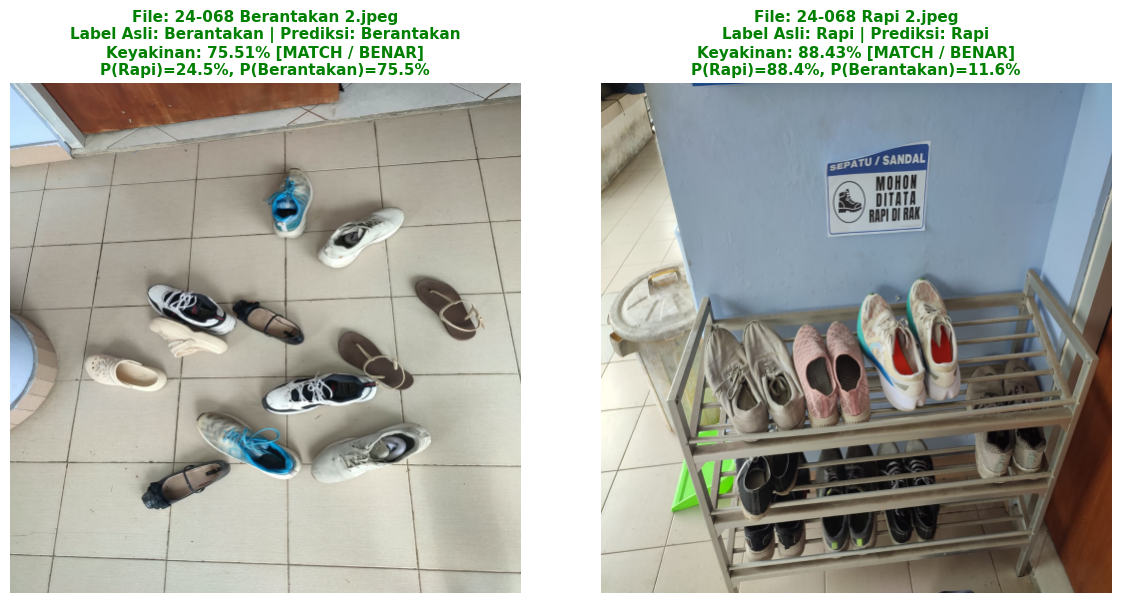

In [5]:
test_samples = [
    ("dataset_baru/berantakan/24-068 Berantakan 2.jpeg", "Berantakan"),
    ("dataset_baru/rapi/24-068 Rapi 2.jpeg", "Rapi")
]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for idx, (fpath, ground_truth) in enumerate(test_samples):
    feats_dict, img_rgb, _ = ekstraksi_14_fitur(fpath)
    
    # Ambil vektor 14 fitur sesuai urutan
    feat_vector = np.array([[feats_dict[col] for col in features]])
    
    # Transformasi Z-score
    feat_sc = scaler.transform(feat_vector)
    
    # Prediksi kelas & probabilitas keyakinan
    pred_idx = svm_clf.predict(feat_sc)[0]
    pred_proba = svm_clf.predict_proba(feat_sc)[0]
    
    pred_label = "Berantakan" if pred_idx == 1 else "Rapi"
    confidence = pred_proba[pred_idx] * 100
    
    # Visualisasi Foto & Hasil Prediksi
    axes[idx].imshow(img_rgb)
    axes[idx].axis('off')
    status_text = "MATCH / BENAR" if pred_label == ground_truth else "MISMATCH / SALAH"
    color = "green" if pred_label == ground_truth else "red"
    
    title_str = (
        f"File: {os.path.basename(fpath)}\n"
        f"Label Asli: {ground_truth} | Prediksi: {pred_label}\n"
        f"Keyakinan: {confidence:.2f}% [{status_text}]\n"
        f"P(Rapi)={pred_proba[0]*100:.1f}%, P(Berantakan)={pred_proba[1]*100:.1f}%"
    )
    axes[idx].set_title(title_str, fontsize=11, fontweight='bold', color=color)

plt.tight_layout()
plt.show()

## 6. Kesimpulan & Eksplorasi Tingkat Lanjut (Bab 12)

### Ringkasan Pencapaian 14 Fitur Inti Dosen:
1. Seluruh 14 fitur inti (9 momen warna RGB + 5 GLCM Haralick) berhasil diimplementasikan dari nol (*from scratch*) tanpa menggunakan library instan GLCM tertutup.
2. Dataset sebesar 194 citra berhasil diekstrak dan disimpan dalam `hasil_ekstraksi_fitur_citra.csv` tanpa data hilang (*0 missing values*).
3. Klasifikasi Machine Learning SVM RBF berhasil mencapai **Akurasi Pengujian 79.49%** (31 dari 39 citra uji benar) dengan **5-Fold Cross Validation 78.89%**.

---

### Jembatan Menuju Bab 12 (Eksperimen Peningkatan Akurasi $\ge 90\%$):
Pada dataset dunia nyata sebanyak 194 citra dengan sudut pandang dan variasi pencahayaan yang kompleks, representasi 14 fitur dasar memiliki batas kapasitas informasi di kisaran $75\% - 80\%$.

Oleh karena itu, pada **Bab 12**, dilakukan eksplorasi lanjutan menggunakan:
1. **Fusi 84 Fitur Multimodal:** Menggabungkan 45 fitur handcrafted warna & tekstur multi-jarak + 4 fitur spasial deteksi objek YOLO + 35 fitur Deep Semantics PCA MobileNetV2.
2. **Deep Learning YOLOv8 Classification (`yolov8n-cls`):** Fine-tuning model konvolusional mutakhir.
3. **Hasil:** Akurasi meningkat drastis hingga **97.50%** (YOLOv8) dan **97.44%** (SVM RBF Fusi 84 Fitur)!

Dokumentasi lengkap dan laporan interaktif dapat diakses pada web statis:
**https://jaidan2212.github.io/PSD/ekstraksi_fitur_citra_digital.html**